--- Fit Results for Relaxation Analysis: 100% Glycerol ---
Calculated T1: 18.67 ± 0.21 ms
Fitted plateau (a): 5.40 ± 0.08 V
Fitted amplitude (k): 13.15 ± 0.07 V



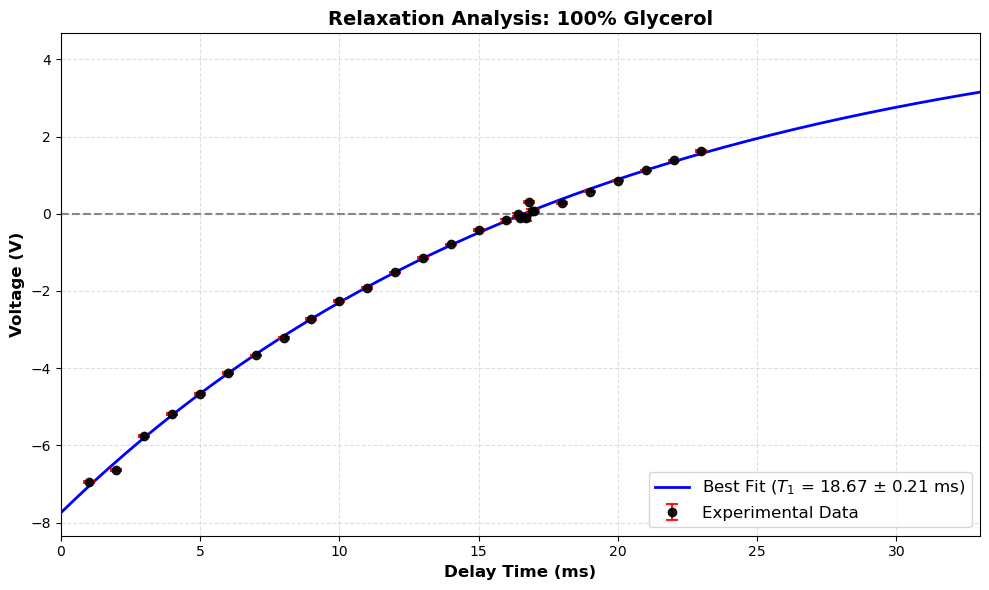

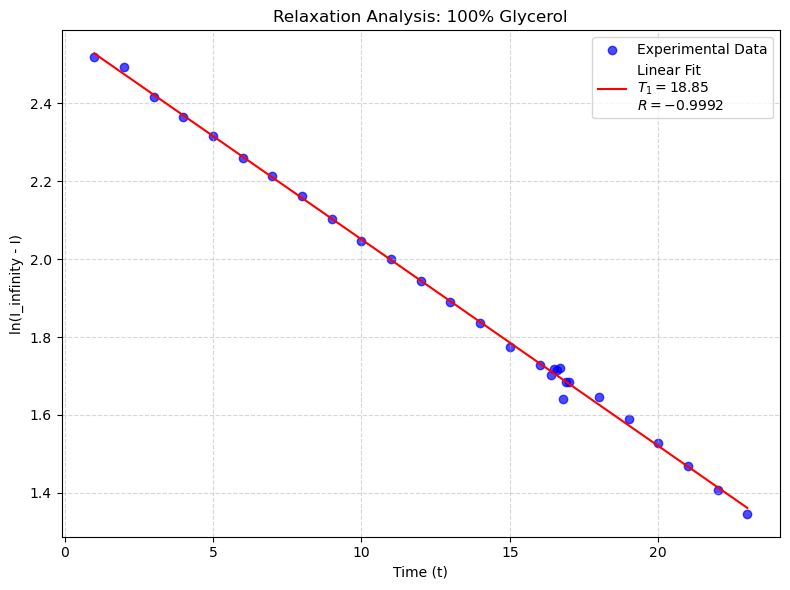

--- Fit Results for Relaxation Analysis: 90% Glycerol ---
Calculated T1: 53.93 ± 0.56 ms
Fitted plateau (a): 9.06 ± 0.12 V
Fitted amplitude (k): 18.30 ± 0.11 V



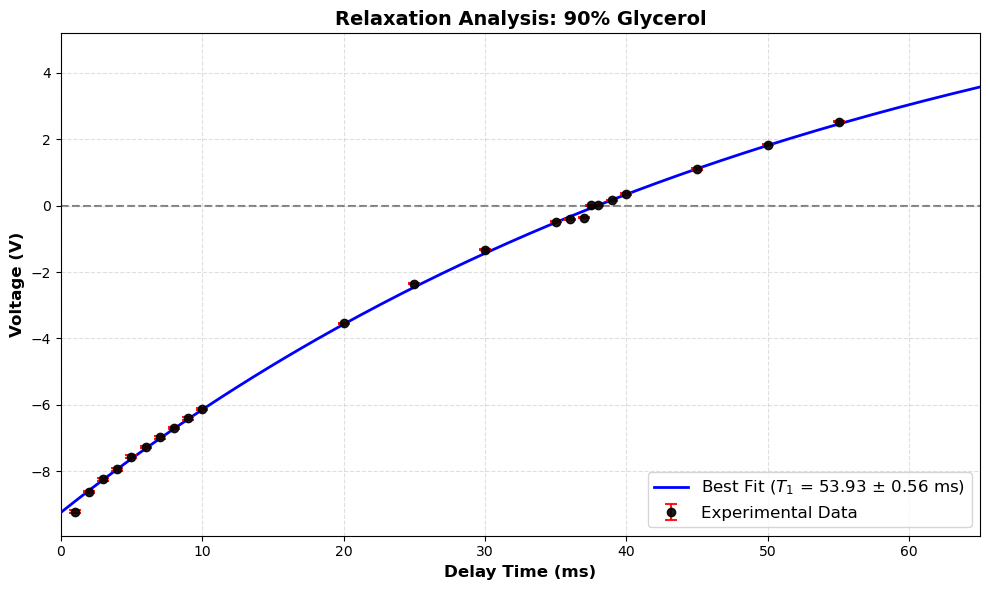

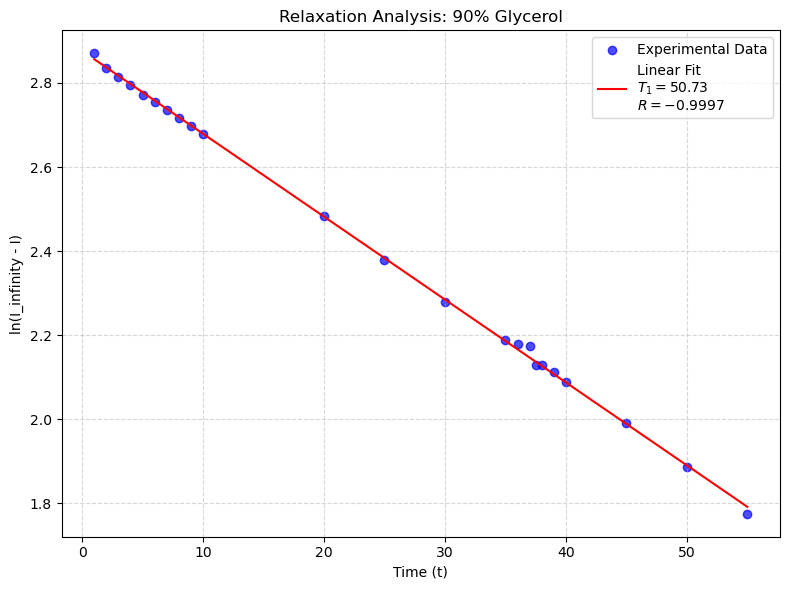

--- Fit Results for Relaxation Analysis: 75% Glycerol ---
Calculated T1: 108.51 ± 2.51 ms
Fitted plateau (a): 15.46 ± 0.42 V
Fitted amplitude (k): 27.52 ± 0.38 V



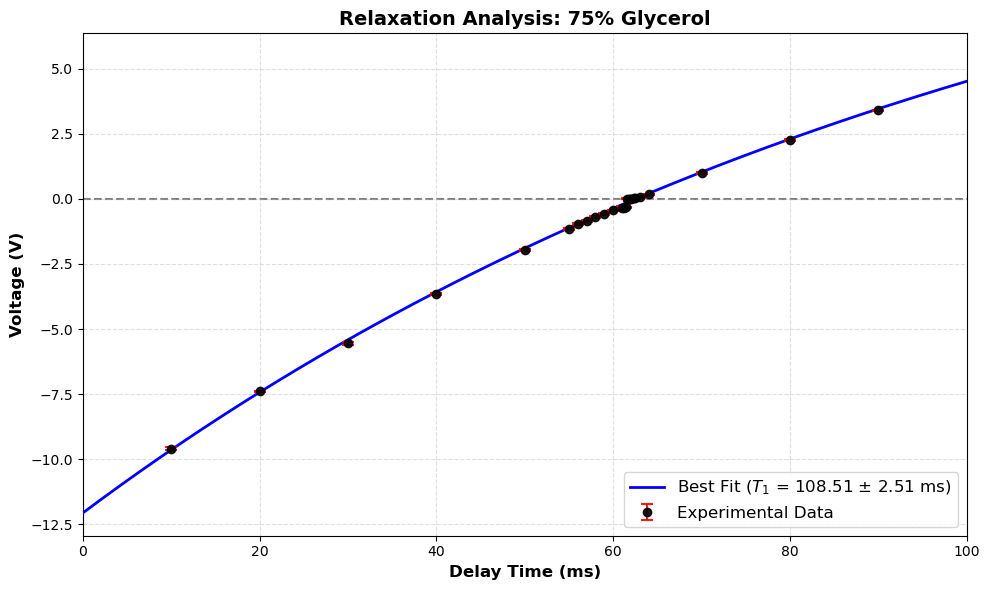

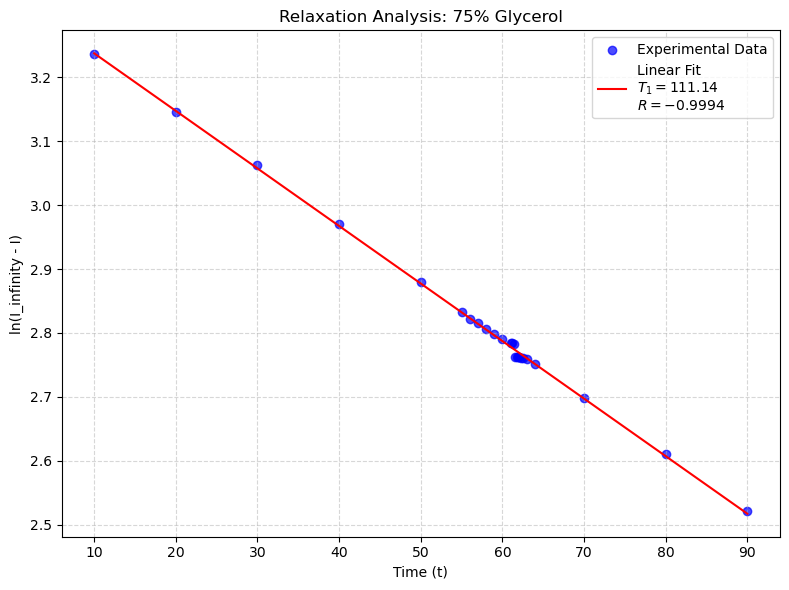

--- Fit Results for Relaxation Analysis: 50% Glycerol ---
Calculated T1: 288.93 ± 1.67 ms
Fitted plateau (a): 6.02 ± 0.04 V
Fitted amplitude (k): 12.33 ± 0.03 V



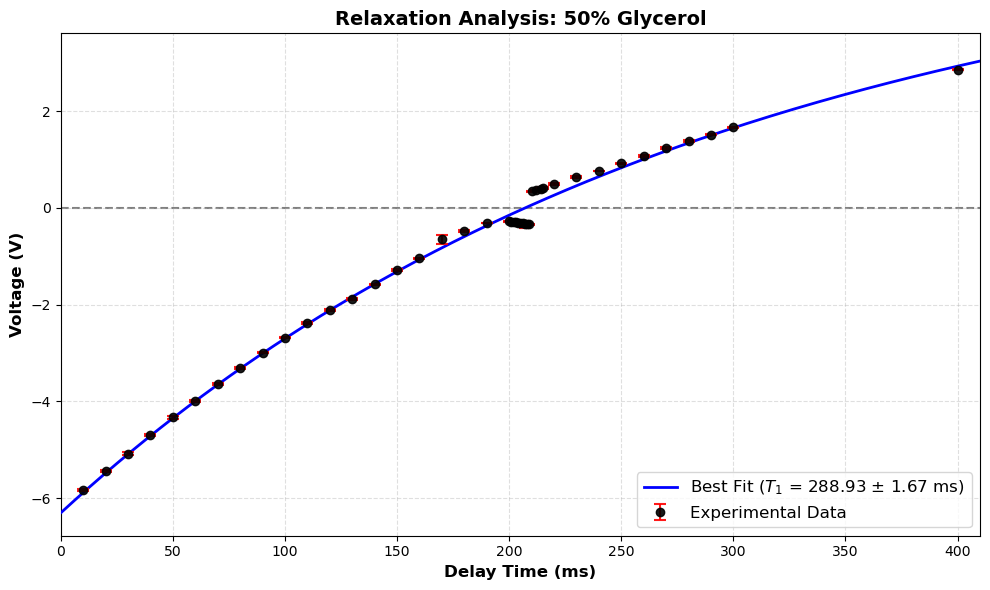

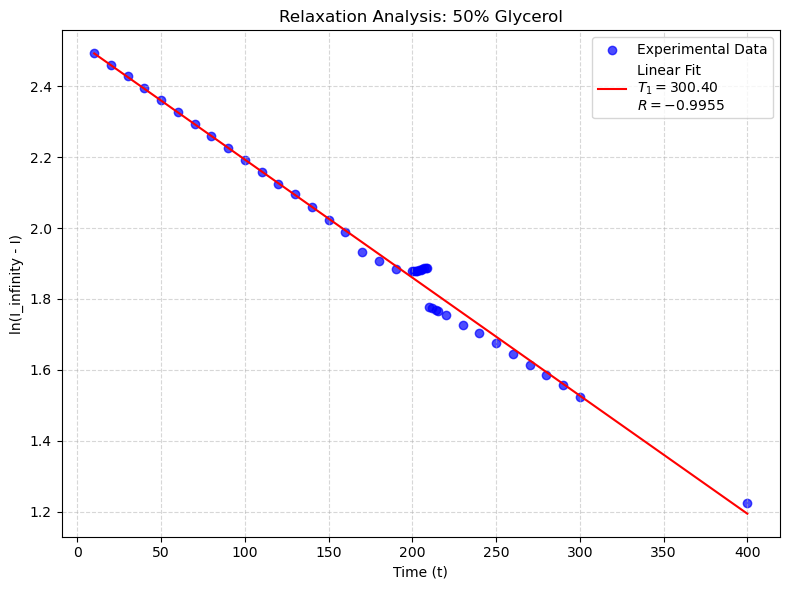

--- Fit Results for Relaxation Analysis: 25% Glycerol ---
Calculated T1: 300.00 ± 2.78 ms
Fitted plateau (a): 2.33 ± 0.03 V
Fitted amplitude (k): 6.80 ± 0.02 V



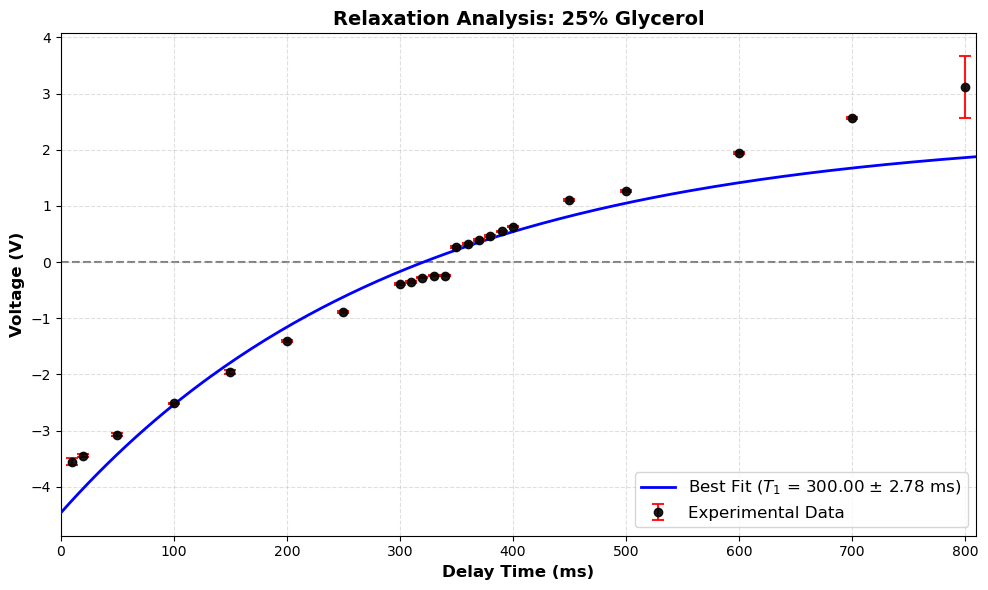

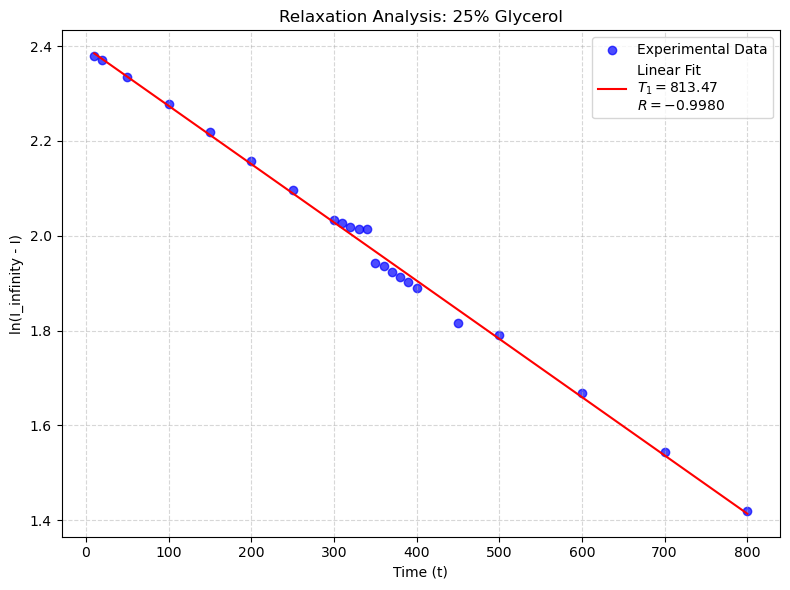

--- Fit Results for Relaxation Analysis: 12.5% Glycerol ---
Calculated T1: 300.00 ± 1.89 ms
Fitted plateau (a): 4.91 ± 0.03 V
Fitted amplitude (k): 15.20 ± 0.03 V



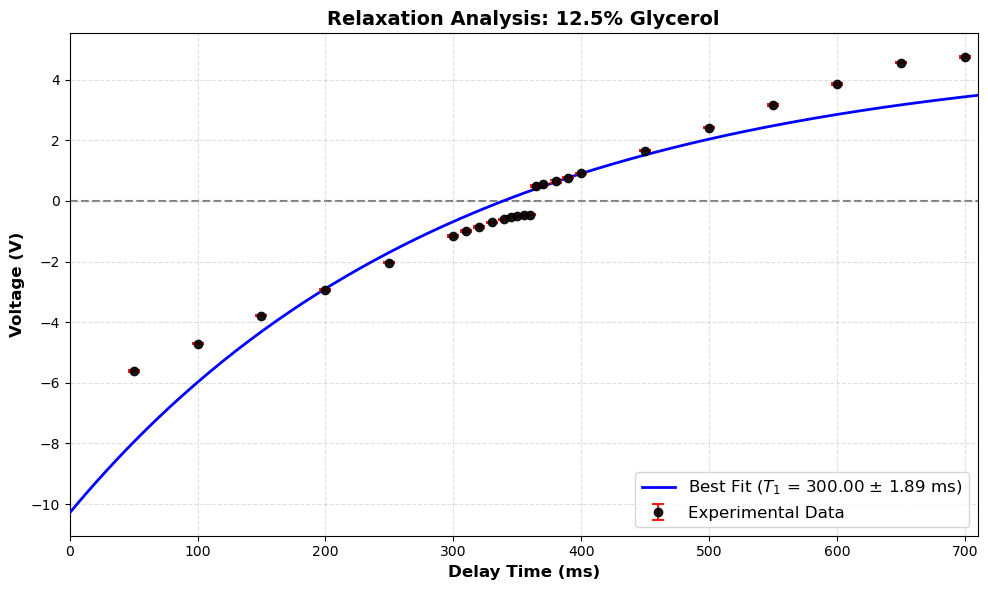

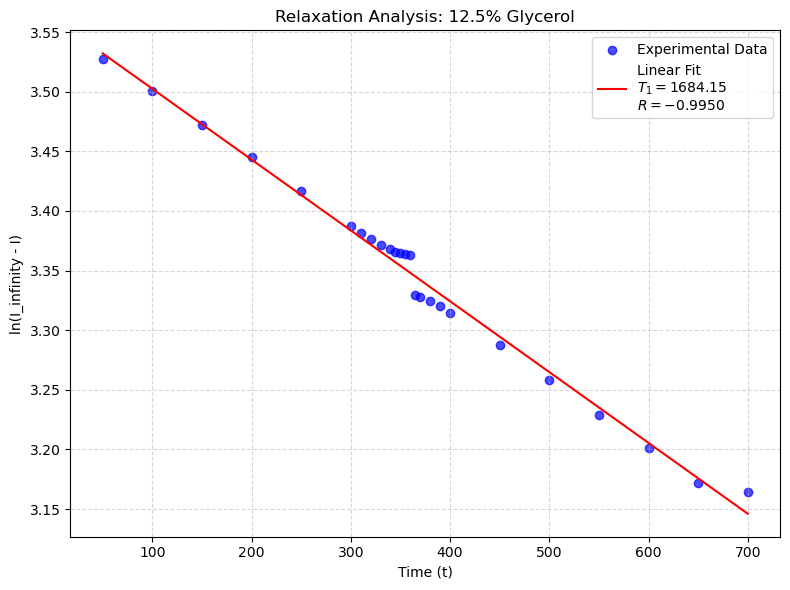

--- Fit Results for Relaxation Analysis: 6.25% Glycerol ---
Calculated T1: 300.00 ± 2.49 ms
Fitted plateau (a): 4.50 ± 0.03 V
Fitted amplitude (k): 14.69 ± 0.06 V



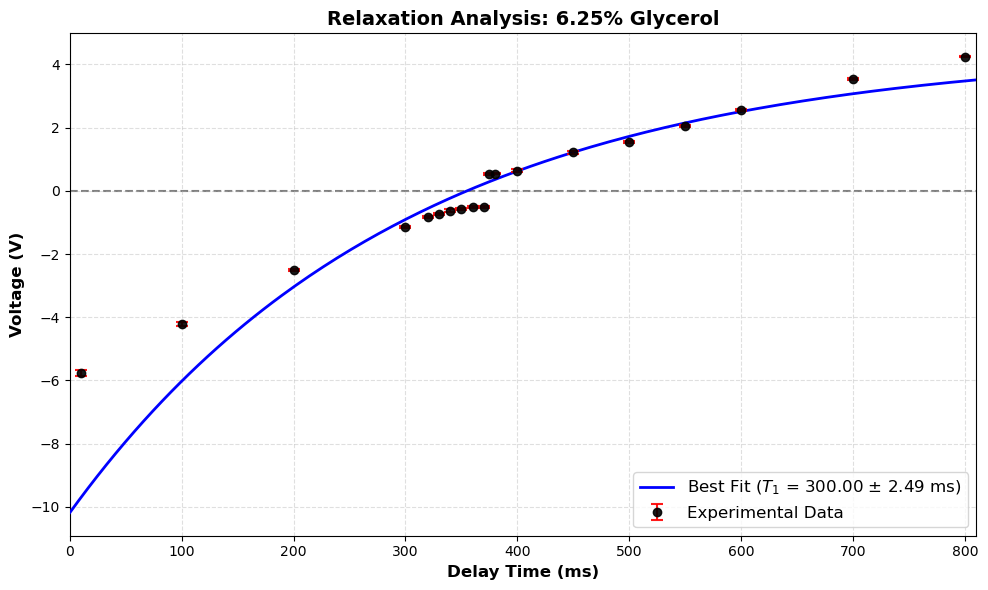

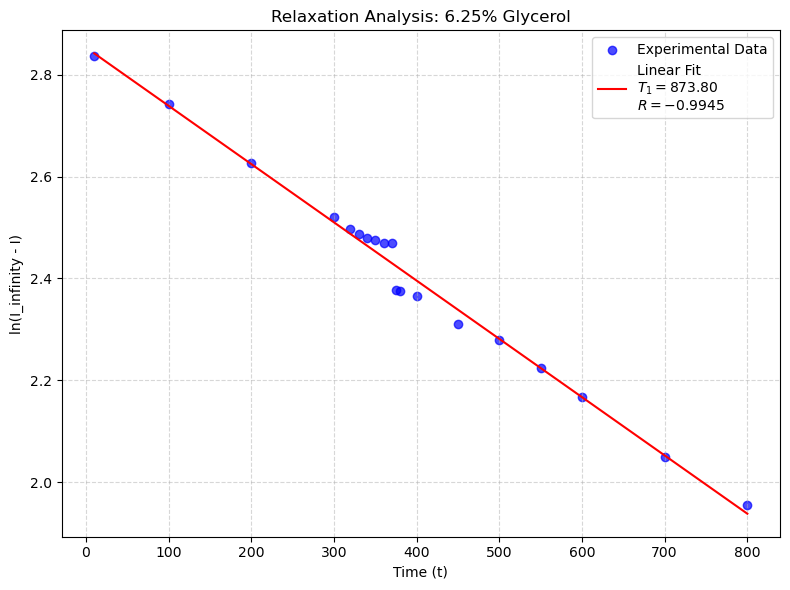

--- Fit Results for Relaxation Analysis: 3.125%% Glycerol ---
Calculated T1: 300.00 ± 3.06 ms
Fitted plateau (a): 3.59 ± 0.04 V
Fitted amplitude (k): 12.24 ± 0.06 V



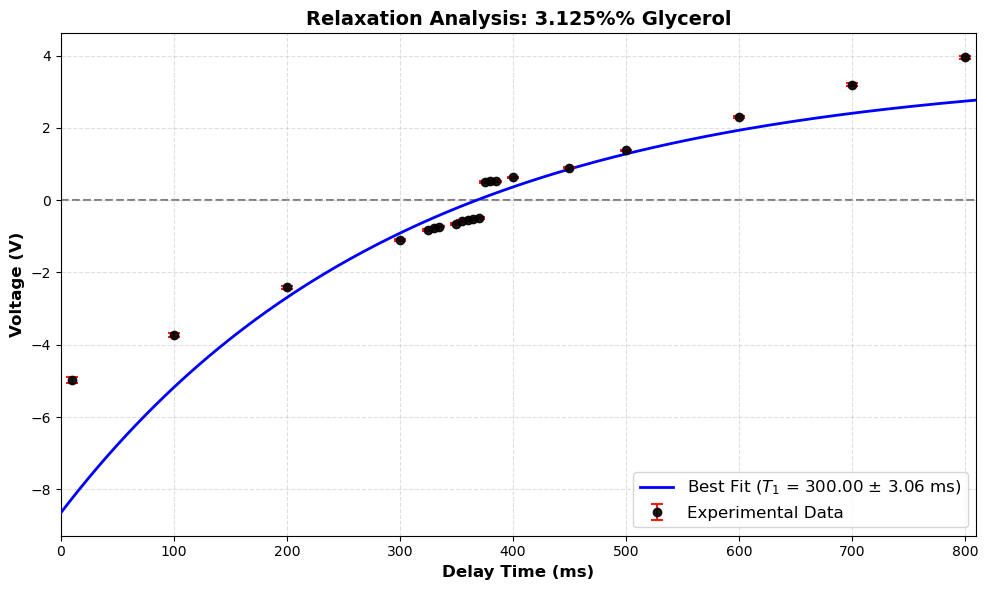

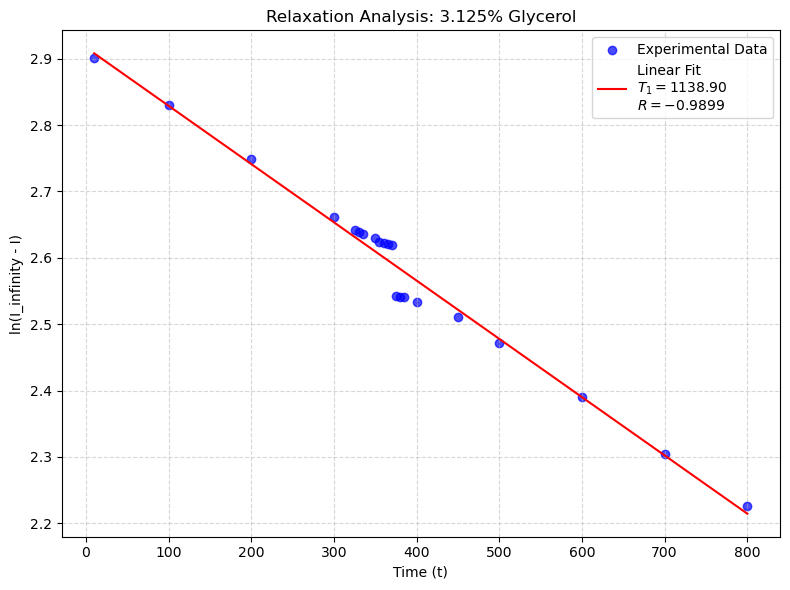

--- Fit Results for Relaxation Analysis: 1.3%% Glycerol ---
Calculated T1: 300.00 ± 1.92 ms
Fitted plateau (a): 4.09 ± 0.02 V
Fitted amplitude (k): 12.14 ± 0.04 V



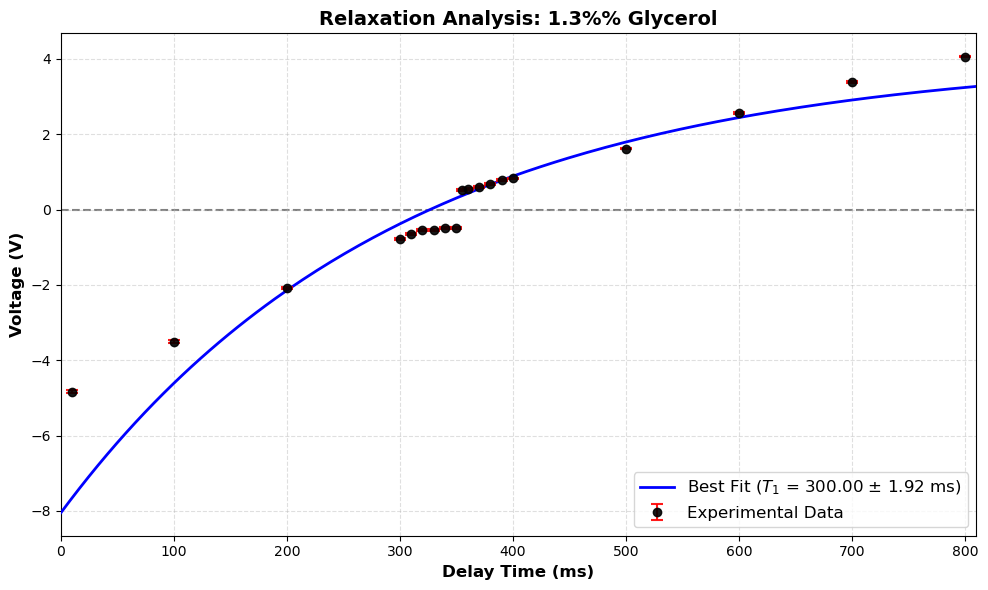

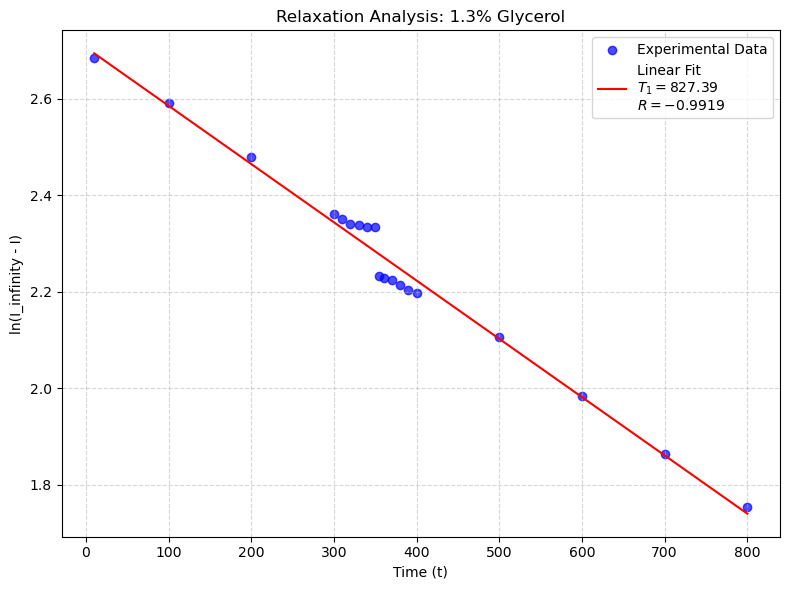

--- Fit Results for Relaxation Analysis: Distilled Water ---
Calculated T1: 300.00 ± 2.37 ms
Fitted plateau (a): 3.78 ± 0.02 V
Fitted amplitude (k): 11.23 ± 0.04 V



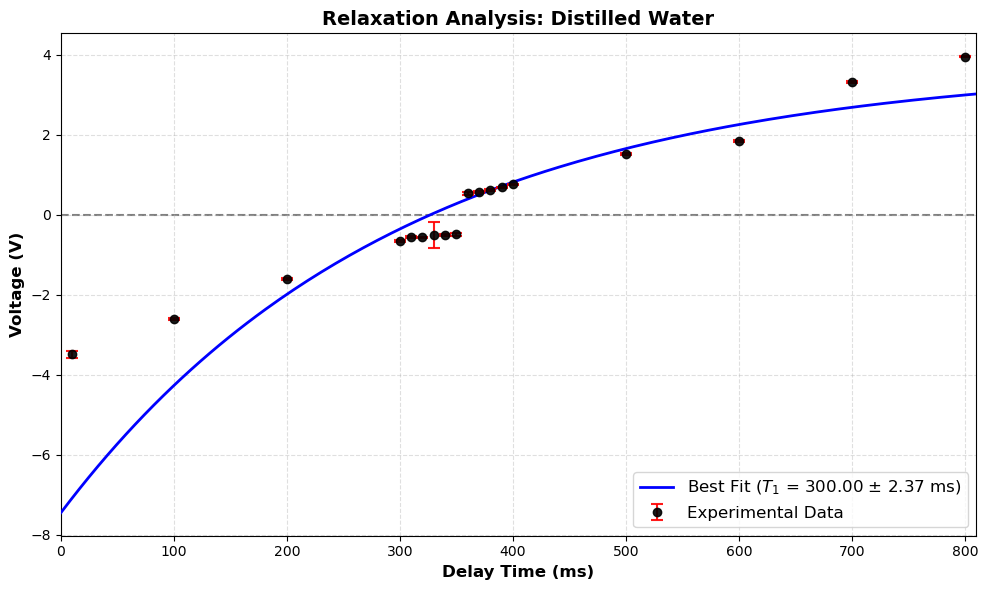

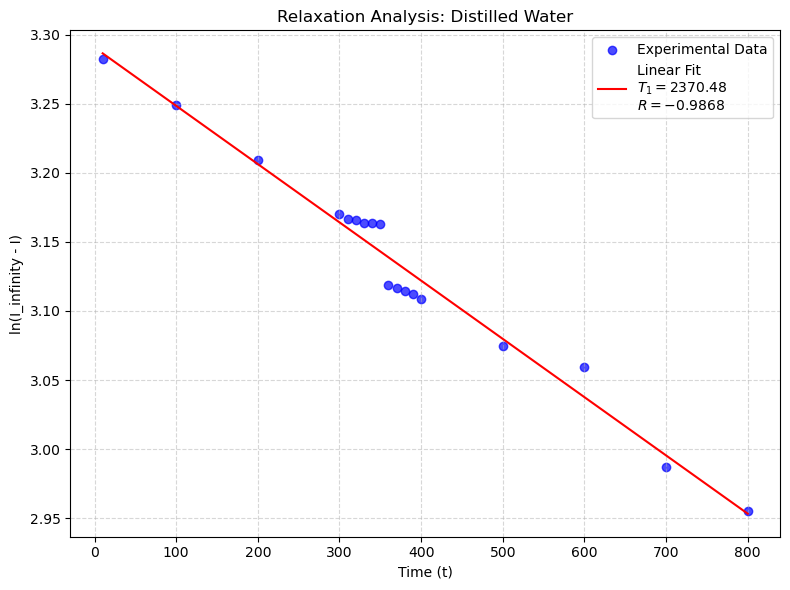

(np.float64(2370.4825938837116), np.float64(-0.9868390471202768))

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy.optimize import curve_fit

def analyze_t1(file_path, plot_title):
    """
    Analyzes T1 relaxation data from a CSV file.
    Uses the first 3 columns: Time, Voltage, and Std Dev.
    """
    # 1. Load data
    df = pd.read_csv(file_path)

    # 2. Extract first three columns and clean NaNs
    time = df.iloc[:, 0].values
    voltage = df.iloc[:, 1].values
    mask = ~np.isnan(time) & ~np.isnan(voltage)
    time, voltage = time[mask], voltage[mask]

    # 3. Determine the best Asymptote (I_infinity) for accurate linearization
    def model(t, A, B, T1):
        return A - B * np.exp(-t / T1)
    
    try:
        popt, _ = curve_fit(model, time, voltage, p0=[max(voltage)*1.1, 2*max(voltage), 25])
        I_inf = popt[0]
    except:
        I_inf = max(voltage) * 1.05 # Fallback if fit fails

    # 4. Linearization
    y_lin = np.log(I_inf - voltage)
    x_lin = time

    # 5. Linear Regression to get T1 and R
    res = linregress(x_lin, y_lin)
    t1_calc = -1 / res.slope
    r_val = res.rvalue

    # 6. Create the Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(x_lin, y_lin, color='blue', label='Experimental Data', alpha=0.7)
    
    legend_info = f'Linear Fit\n$T_1 = {t1_calc:.2f}$\n$R = {r_val:.4f}$'
    plt.plot(x_lin, res.slope * x_lin + res.intercept, 'r-', label=legend_info)

    plt.xlabel("Time (t)")
    plt.ylabel("ln(I_infinity - I)")
    plt.title(plot_title)
    plt.legend(loc='best', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    return t1_calc, r_val



def process_and_plot(filename, title):
    # 1. Load and Clean Data
    data = pd.read_csv(filename, encoding='windows-1252')
    data = data.iloc[:, 0:3].dropna()

    # Extract columns
    t = data.iloc[:, 0].values        
    V = data.iloc[:, 1].values   

    # Extract 3rd column (Standard Deviation) and convert mV to V
    std_dev = data.iloc[:, 2].values / 1000 
    std_dev = np.where(std_dev == 0, 1e-9, std_dev) # Prevent divide-by-zero errors

    # 2. Define the Mathematical Model
    def recovery_model(t, a, k, T1):
        return a - k * np.exp(-t / T1)

    # 3. Initial Guesses and Bounds
    p0 = [7.0, 14.0, 108.0]
    bounds = ([0, 0, 0], [20, 30, 300])

    # 4. Perform the Curve Fit
    popt, pcov = curve_fit(
        recovery_model, t, V, 
        p0=p0, 
        sigma=std_dev, 
        absolute_sigma=True,
        bounds=bounds
    )

    a_fit, k_fit, T1_fit = popt
    perr = np.sqrt(np.diag(pcov))
    a_err, k_err, T1_err = perr  

    print(f"--- Fit Results for {title} ---")
    print(f"Calculated T1: {T1_fit:.2f} ± {T1_err:.2f} ms")
    print(f"Fitted plateau (a): {a_fit:.2f} ± {a_err:.2f} V")
    print(f"Fitted amplitude (k): {k_fit:.2f} ± {k_err:.2f} V\n")

    # 5. Plotting the Graph
    plt.figure(figsize=(10, 6))

    # Plot raw data with highly visible red error bars
    plt.errorbar(t, V, yerr=std_dev, fmt='o', color='black', 
                 ecolor='red', elinewidth=1.5, capsize=4, capthick=1.5, 
                 label='Experimental Data', alpha=0.9, zorder=5)

    # Generate a smooth curve for the fitted line
    t_smooth = np.linspace(0, max(t) + 20, 200) 

    # Plot the best fit curve AND add the calculated error to the legend
    plt.plot(t_smooth, recovery_model(t_smooth, *popt), color='blue', linewidth=2, 
             label=f'Best Fit ($T_1$ = {T1_fit:.2f} $\pm$ {T1_err:.2f} ms)', zorder=3)

    # Formatting the graph
    plt.axhline(0, color='gray', linestyle='--', zorder=1)
    plt.xlim(0, max(t) + 10) 
    plt.xlabel('Delay Time (ms)', fontsize=12, fontweight='bold')
    plt.ylabel('Voltage (V)', fontsize=12, fontweight='bold')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend(fontsize=12, loc='lower right')
    plt.grid(alpha=0.4, linestyle='--')

    # Show the plot instead of saving it 
    plt.tight_layout()
    plt.show()
    # Process 100% Glycerol using the matching file path
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\100% glycerol\T_1 csv.csv", "Relaxation Analysis: 100% Glycerol")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\100% glycerol\T_1 csv.csv", "Relaxation Analysis: 100% Glycerol")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\90% glycerol\T1 90.csv", "Relaxation Analysis: 90% Glycerol")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\90% glycerol\T1 90.csv", "Relaxation Analysis: 90% Glycerol")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\75% glycerol\T175.csv", "Relaxation Analysis: 75% Glycerol")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\75% glycerol\T175.csv", "Relaxation Analysis: 75% Glycerol")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\50% glycerol\T1.csv", "Relaxation Analysis: 50% Glycerol")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\50% glycerol\T1.csv", "Relaxation Analysis: 50% Glycerol")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\25% Glyerol\T1.csv", "Relaxation Analysis: 25% Glycerol")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\25% Glyerol\T1.csv",  "Relaxation Analysis: 25% Glycerol")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\6.25% glycerol\Potentially 6.1 was measured thinking it was 12.5.csv", "Relaxation Analysis: 12.5% Glycerol")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\6.25% glycerol\Potentially 6.1 was measured thinking it was 12.5.csv",  "Relaxation Analysis: 12.5% Glycerol")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\6.25% glycerol\T1.csv", "Relaxation Analysis: 6.25% Glycerol")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\6.25% glycerol\T1.csv", "Relaxation Analysis: 6.25% Glycerol")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\3.125% Glycerol\T13.1.csv", "Relaxation Analysis: 3.125%% Glycerol")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\3.125% Glycerol\T13.1.csv", "Relaxation Analysis: 3.125% Glycerol")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\1.3% Glycerol\T11.03.csv", "Relaxation Analysis: 1.3%% Glycerol")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\1.3% Glycerol\T11.03.csv", "Relaxation Analysis: 1.3% Glycerol")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\Distilled water\water.csv", "Relaxation Analysis: Distilled Water")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\Distilled water\water.csv", "Relaxation Analysis: Distilled Water")

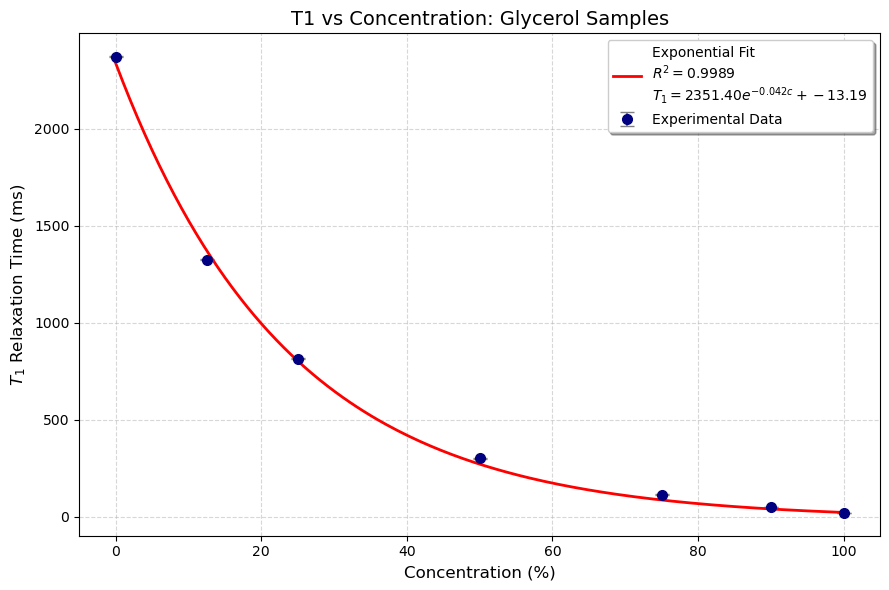

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def plot_t1_trend(csv_path, graph_title):
    """
    Plots T1 against Concentration.
    Expects first 3 columns: Concentration, T1, and T1 Error.
    """
    # 1. Load the data
    df = pd.read_csv(csv_path)
    
    # 2. Extract the first 3 columns strictly
    x_raw = df.iloc[:, 0].values
    y_raw = df.iloc[:, 1].values
    err_raw = df.iloc[:, 2].values
    
    # 3. Clean NaNs and handle empty rows
    mask = ~np.isnan(x_raw) & ~np.isnan(y_raw)
    x, y, err = x_raw[mask], y_raw[mask], err_raw[mask]
    
    # Sort by concentration (x) so the plotting line is smooth
    idx = np.argsort(x)
    x, y, err = x[idx], y[idx], err[idx]

    # 4. Exponential Growth Model: T1 = A * exp(-K * concentration) + C
    # As concentration (x) -> 0, T1 (y) -> A + C
    # As concentration (x) increases, T1 (y) drops towards C
    def exp_model(c, A, K, C):
        return A * np.exp(-K * c) + C

    # 5. Fit the Curve
    # Guesses: A (diff between max and min), K (rate), C (value at high conc)
    p0 = [max(y) - min(y), 0.05, min(y)]
    
    try:
        popt, _ = curve_fit(exp_model, x, y, p0=p0, sigma=err, absolute_sigma=True)
        A, K, C = popt
        
        # Calculate R-squared
        residuals = y - exp_model(x, *popt)
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((y - np.mean(y))**2)
        r_squared = 1 - (ss_res / ss_tot)
        
        # Smooth curve for plotting
        x_fit = np.linspace(x.min(), x.max(), 200)
        y_fit = exp_model(x_fit, *popt)
        
        fit_label = f'Exponential Fit\n$R^2 = {r_squared:.4f}$\n$T_1 = {A:.2f} e^{{-{K:.3f}c}} + {C:.2f}$'
    except Exception as e:
        print(f"Curve fit failed: {e}")
        x_fit, y_fit, fit_label = None, None, "Fit Failed"

    # 6. Plotting
    plt.figure(figsize=(9, 6))
    
    # Plot experimental data
    plt.errorbar(x, y, yerr=err, fmt='o', color='navy', 
                 ecolor='gray', capsize=5, label='Experimental Data', markersize=7)
    
    # Plot fit line
    if x_fit is not None:
        plt.plot(x_fit, y_fit, 'r-', linewidth=2, label=fit_label)

    plt.xlabel('Concentration (%)', fontsize=12)
    plt.ylabel('$T_1$ Relaxation Time (ms)', fontsize=12)
    plt.title(graph_title, fontsize=14)
    plt.legend(loc='best', frameon=True, shadow=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

# --- CALL THE FUNCTION BELOW ---
# IMPORTANT: Ensure the line below is NOT indented (start at the very left)
plot_t1_trend(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\master\master.csv", "T1 vs Concentration: Glycerol Samples")

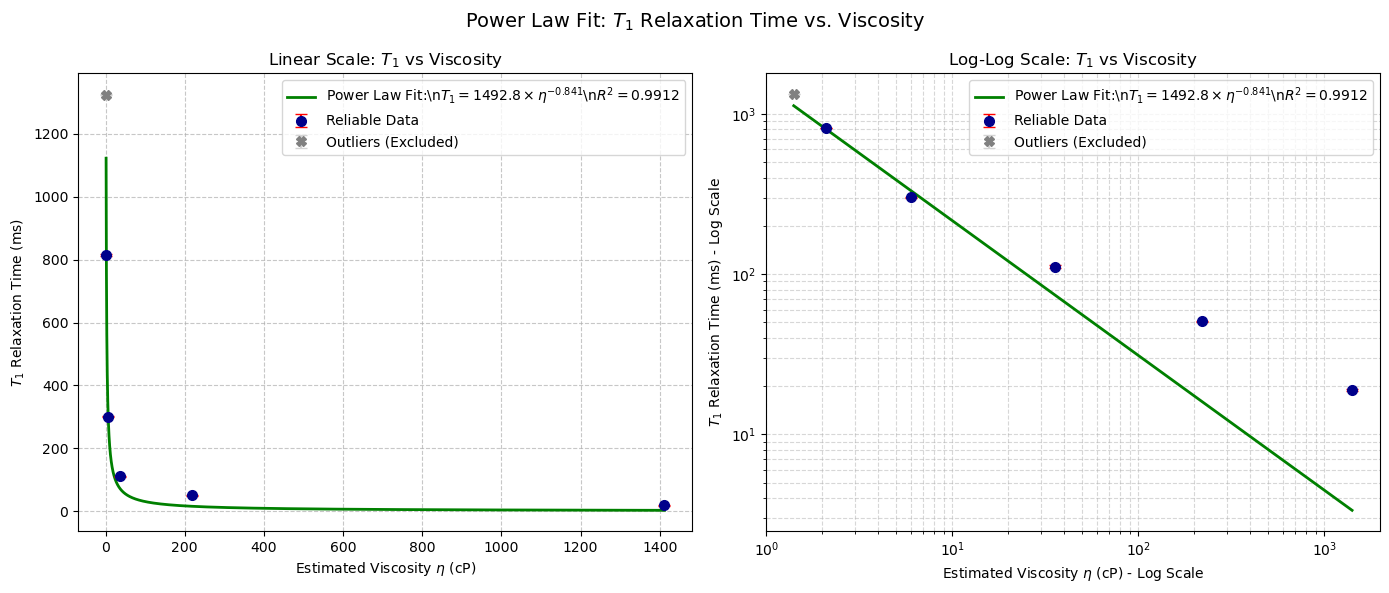

Fit equation: T1 = 1492.83 * viscosity ^ -0.8407
R-squared: 0.9912


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# 1. Read your data directly from your local master CSV file
file_path = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\master\master.csv"

try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"Error: Could not find the file at {file_path}. Please check the path.")
    exit()

# Exact column names based on your uploaded screenshot
conc_col_name = 'Concentration'  
t1_col_name = 'T1'               
err_col_name = 'Error'           

# --- THE FIX: Clean the data before doing any math ---
# Force columns to numeric (turns accidental spaces/text into NaNs)
df[conc_col_name] = pd.to_numeric(df[conc_col_name], errors='coerce')
df[t1_col_name] = pd.to_numeric(df[t1_col_name], errors='coerce')
df[err_col_name] = pd.to_numeric(df[err_col_name], errors='coerce')

# Drop those blank rows at the bottom of the CSV
df = df.dropna(subset=[conc_col_name, t1_col_name, err_col_name])

# Now safely extract the arrays
conc = df[conc_col_name].values
t1 = df[t1_col_name].values
err = df[err_col_name].values

# 2. Reference data for Glycerol-Water viscosity at 20°C
ref_conc = np.array([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
ref_visc = np.array([1.005, 1.31, 1.76, 2.50, 3.72, 6.00, 10.8, 22.5, 60.1, 219, 1412])

# Create an interpolation function (with fill_value to prevent out-of-bounds crashes)
interp_func = interp1d(ref_conc, np.log10(ref_visc), kind='cubic', fill_value="extrapolate")

# Calculate estimated viscosities for the experimental concentrations
viscosities = 10**(interp_func(conc))

# 3. Separate good data from outliers for the curve fit
# We round the concentration array slightly to ensure exact matches for floating-point numbers
outlier_mask = np.isin(np.round(conc, 3), [12.5, 6.1, 3.125, 1.05])
good_mask = ~outlier_mask

conc_good = conc[good_mask]
t1_good = t1[good_mask]
visc_good = viscosities[good_mask]
err_good = err[good_mask]

conc_out = conc[outlier_mask]
t1_out = t1[outlier_mask]
visc_out = viscosities[outlier_mask]
err_out = err[outlier_mask]

# 4. Curve fitting (Power Law: T1 = a * viscosity^b)
def power_law(x, a, b):
    return a * (x ** b)

# Fit only the reliable data
popt, pcov = curve_fit(power_law, visc_good, t1_good, p0=[2000, -1])
a_fit, b_fit = popt

# Generate points for the smooth fitted curve
visc_fit_line = np.logspace(np.log10(viscosities.min()), np.log10(viscosities.max()), 500)
t1_fit_line = power_law(visc_fit_line, a_fit, b_fit)

# Calculate R-squared for the fit on good data
residuals = t1_good - power_law(visc_good, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((t1_good - np.mean(t1_good))**2)
r_squared = 1 - (ss_res / ss_tot)

# 5. Set up the plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Using an 'rf' string here fixes that annoying \p invalid escape sequence warning
fit_label = rf'Power Law Fit:\n$T_1 = {a_fit:.1f} \times \eta^{{{b_fit:.3f}}}$\n$R^2 = {r_squared:.4f}$'

# Plot 1: Linear Scale
ax1.plot(visc_fit_line, t1_fit_line, 'g-', lw=2, label=fit_label)
ax1.errorbar(visc_good, t1_good, yerr=err_good, fmt='o', color='darkblue', ecolor='red', capsize=4, markersize=7, label='Reliable Data')
if len(conc_out) > 0:
    ax1.errorbar(visc_out, t1_out, yerr=err_out, fmt='X', color='gray', ecolor='lightgray', capsize=4, markersize=7, label='Outliers (Excluded)')
ax1.set_xlabel(rf'Estimated Viscosity $\eta$ (cP)')
ax1.set_ylabel(rf'$T_1$ Relaxation Time (ms)')
ax1.set_title(rf'Linear Scale: $T_1$ vs Viscosity')
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend()

# Plot 2: Log-Log Scale
ax2.plot(visc_fit_line, t1_fit_line, 'g-', lw=2, label=fit_label)
ax2.errorbar(visc_good, t1_good, yerr=err_good, fmt='o', color='darkblue', ecolor='red', capsize=4, markersize=7, label='Reliable Data')
if len(conc_out) > 0:
    ax2.errorbar(visc_out, t1_out, yerr=err_out, fmt='X', color='gray', ecolor='lightgray', capsize=4, markersize=7, label='Outliers (Excluded)')
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel(rf'Estimated Viscosity $\eta$ (cP) - Log Scale')
ax2.set_ylabel(rf'$T_1$ Relaxation Time (ms) - Log Scale')
ax2.set_title(rf'Log-Log Scale: $T_1$ vs Viscosity')
ax2.grid(True, which="both", ls="--", alpha=0.5)
ax2.legend()

plt.suptitle(rf'Power Law Fit: $T_1$ Relaxation Time vs. Viscosity', fontsize=14)
plt.tight_layout()

# Save the plot to your local Desktop E2 folder
plt.savefig(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\master\t1_viscosity_curve_fit.png", dpi=300)
plt.show()

print(f"Fit equation: T1 = {a_fit:.2f} * viscosity ^ {b_fit:.4f}")
print(f"R-squared: {r_squared:.4f}")